# RPS Custom CNN From Scratch



In [1]:
import os, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

SEED = 123
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


In [3]:
from google.colab import files

uploaded = files.upload()

Saving dataset.zip to dataset (1).zip


In [4]:
import zipfile
import os

zip_path = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/rps_data')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [5]:
from pathlib import Path

search_dir = Path("/content/rps_data")
DATA_DIR = None

for root, dirs, files_list in os.walk(search_dir):
    if all(c in dirs for c in ["rock", "paper", "scissors"]):
        DATA_DIR = Path(root)
        break

if DATA_DIR is None:
    raise FileNotFoundError("Rock, Paper, Scissors folders not found!")

print("Correct Dataset Path:", DATA_DIR)

Correct Dataset Path: /content/rps_data/dataset


In [8]:
from pathlib import Path

DATA_DIR = Path("/content/rps_data/dataset")
CLASS_NAMES = ["rock", "paper", "scissors"]
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_DIR}. Upload and extract your ZIP first.")

file_paths, labels = [], []
for class_id, class_name in enumerate(CLASS_NAMES):
    folder = DATA_DIR / class_name
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing class folder: {folder}")
    images = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}]
    print(f"{class_name}: {len(images)} images")
    for p in images:
        file_paths.append(str(p)); labels.append(class_id)

file_paths = np.array(file_paths)
labels = np.array(labels, dtype=np.int32)
if len(file_paths) == 0:
    raise ValueError("No images found in the three class folders.")

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    file_paths, labels, test_size=0.30, random_state=SEED, stratify=labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, random_state=SEED, stratify=temp_labels
)

for split_name, split_y in [("Train", train_labels), ("Validation", val_labels), ("Test", test_labels)]:
    print(split_name, len(split_y), {CLASS_NAMES[i]: int((split_y == i).sum()) for i in range(3)})


rock: 200 images
paper: 200 images
scissors: 200 images
Train 420 {'rock': 140, 'paper': 140, 'scissors': 140}
Validation 90 {'rock': 30, 'paper': 30, 'scissors': 30}
Test 90 {'rock': 30, 'paper': 30, 'scissors': 30}


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label  # 0..255; Rescaling is inside model

def make_dataset(paths, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, y))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

class_ids = np.unique(train_labels)
weights = compute_class_weight(class_weight="balanced", classes=class_ids, y=train_labels)
CLASS_WEIGHTS = {int(k): float(v) for k, v in zip(class_ids, weights)}
print("Class weights:", CLASS_WEIGHTS)


Class weights: {0: 1.0, 1: 1.0, 2: 1.0}


## Custom CNN architecture


In [46]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.06),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
], name="training_augmentation")

inputs = tf.keras.Input(shape=(128, 128, 3))
x = augmentation(inputs)
x = tf.keras.layers.Rescaling(1./255)(x)

# Block 1: convolution + batch normalization + activation + pooling
x = tf.keras.layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.MaxPooling2D()(x)

# Block 2
x = tf.keras.layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.MaxPooling2D()(x)

# Block 3
x = tf.keras.layers.Conv2D(128, 3, padding="same", use_bias=False)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.MaxPooling2D()(x)

# Fully connected classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, use_bias=False)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation("relu")(x)
x = tf.keras.layers.Dropout(0.40)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="RPS_Custom_CNN")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


Model: "RPS_Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,203 (434.39 KB)

 Trainable params: 110,499 (431.64 KB)

 Non-trainable params: 704 (2.75 KB)

## Train: class weights, EarlyStopping, learning-rate reduction, and best checkpoint

In [47]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/rps_custom_cnn_best.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

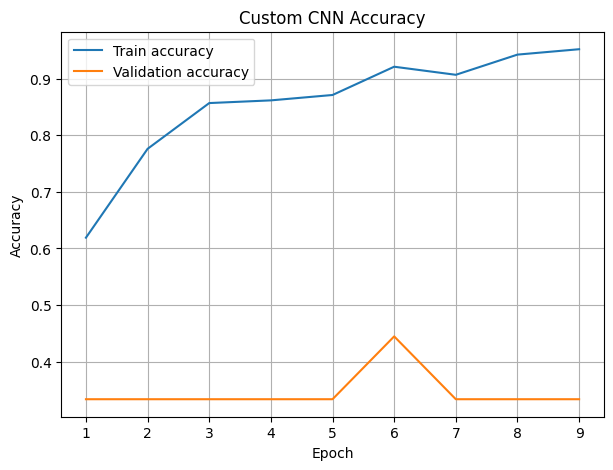

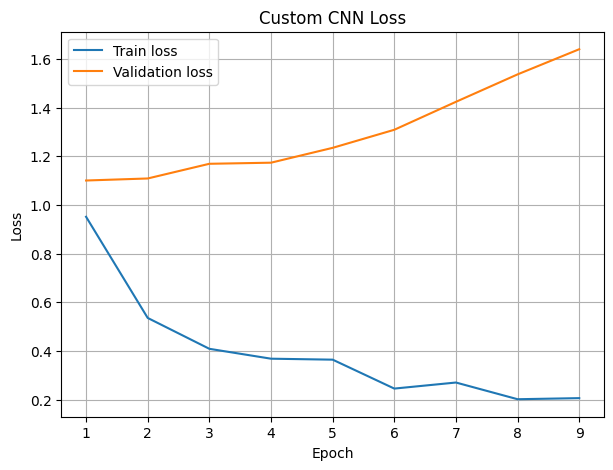

In [12]:
epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(7,5))
plt.plot(epochs, history.history["accuracy"], label="Train accuracy")
plt.plot(epochs, history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Custom CNN Accuracy")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs, history.history["loss"], label="Train loss")
plt.plot(epochs, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Custom CNN Loss")
plt.legend(); plt.grid(True); plt.show()


## Independent test-set evaluation

In [13]:
best_model = tf.keras.models.load_model(checkpoint_path, compile=False)
best_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

test_start = time.time()
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
test_eval_time = time.time() - test_start

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Test evaluation time: {test_eval_time:.2f} seconds")
print(classification_report(
    y_true, y_pred, labels=[0,1,2], target_names=CLASS_NAMES, digits=4, zero_division=0
))


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 758ms/step - accuracy: 0.3333 - loss: 1.1017
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 351ms/step
Test loss: 1.1017
Test accuracy: 0.3333 (33.33%)
Test evaluation time: 2.76 seconds
              precision    recall  f1-score   support

        rock     0.0000    0.0000    0.0000        30
       paper     0.0000    0.0000    0.0000        30
    scissors     0.3333    1.0000    0.5000        30

    accuracy                         0.3333        90
   macro avg     0.1111    0.3333    0.1667        90
weighted avg     0.1111    0.3333    0.1667        90



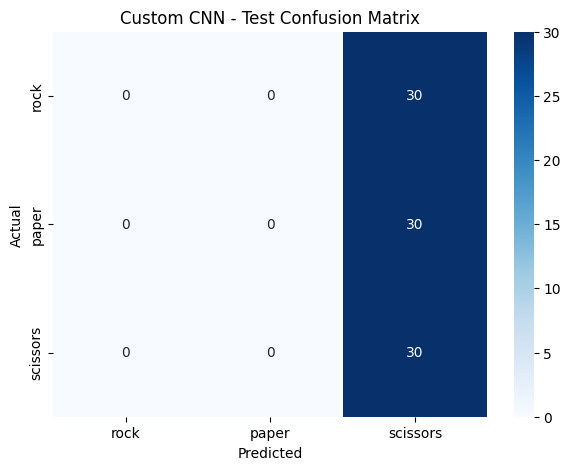

Rows = actual classes; columns = predicted classes.


In [14]:
cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Custom CNN - Test Confusion Matrix")
plt.show()
print("Rows = actual classes; columns = predicted classes.")


In [15]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=[0,1,2], average="weighted", zero_division=0
)
metrics_df = pd.DataFrame([{
    "Model": "Custom CNN from scratch",
    "Test Accuracy": accuracy_score(y_true, y_pred),
    "Weighted Precision": precision,
    "Weighted Recall": recall,
    "Weighted F1": f1,
    "Test Loss": test_loss,
    "Training Time (seconds)": training_time,
    "Test Evaluation Time (seconds)": test_eval_time,
    "Epochs Completed": len(history.history["loss"])
}])
display(metrics_df)

final_path = "/content/rps_custom_cnn_final.keras"
best_model.save(final_path)
metrics_df.to_csv("/content/rps_custom_cnn_metrics.csv", index=False)
print("Saved model:", final_path)
print("Saved metrics: /content/rps_custom_cnn_metrics.csv")


,Model,Test Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Test Loss,Training Time (seconds),Test Evaluation Time (seconds),Epochs Completed
0,Custom CNN from scratch,0.333333,0.111111,0.333333,0.166667,1.101692,311.318113,2.760226,9


Saved model: /content/rps_custom_cnn_final.keras
Saved metrics: /content/rps_custom_cnn_metrics.csv
